<a href="https://colab.research.google.com/github/haero-lee/DS4002-Project3/blob/main/SCRIPTS/EDA_py_documented.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mouse cardiac MRI: exploratory data analysis
**Spider-Sense (DS 4002, team Dataverse)** · Comparing a 2D U-Net with the published UNet 3+ benchmark for left-ventricle segmentation

**Purpose.** Understand the data before modeling: how the files are structured, how good and consistent the expert masks are, how heart size and image quality vary between mice, and what that means for the train/validation/test split.

**Data.** Open-source preclinical dataset from Shah et al. ([GitHub repo](https://github.com/mrphys/Open-Source_Pre-Clinical_Segmentation)): short-axis cine cardiac MRI of 130 mice, one `.h5` file per mouse (about 3.5 GB in total).

**How to run.** Run the cells top to bottom (Runtime → Run all). The first run clones the repo, which takes a few minutes. Everything is saved to `output/` (see the last cell to download it as a zip).

**Reproducibility.**
- The split seed is `42` (step 10), and the exact split is saved to `output/step10_split.csv`.
- `output/run_info.txt` records Python/package versions and the exact commit of the dataset repo used. Copy that commit hash into the final report.
- Analysis settings that were chosen by us are marked `# PARAM` in the code, so they are easy to find and change.

**Steps.** Setup → get data → inspect one file → load helper → overlays (step 7) → labeled frame counts (step 8) → areas (step 9) → split (step 10) → part 2: label quality, heart size/shape, image quality, correlations.

## Setup
Imports, plus the `output/` folders. `save_fig` saves every figure as a PNG (150 dpi) and then displays it. Folders created here:
- `output/` graphs and tables from the main steps
- `output/step7_overlays/` one image per mouse
- `output/part2/` graphs and tables from part 2

In [ ]:
import glob, os
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Everything this notebook saves goes under output/:
#   output/                  -> graphs + CSV tables
#   output/step7_overlays/   -> one image per mouse from step 7
#   output/part2/            -> graphs + CSV tables from the part 2 cell
OUT_DIR = "output"
OVERLAY_DIR = os.path.join(OUT_DIR, "step7_overlays")
os.makedirs(OVERLAY_DIR, exist_ok=True)

def save_fig(name, folder=OUT_DIR, show=True):
    """Save the current figure as a PNG, then show it (or just close it)."""
    path = os.path.join(folder, name)
    plt.savefig(path, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close()
    return path


## Get the data
Clone the dataset repository (about 2 GB download, 3.5 GB on disk). **Colab deletes this folder when the runtime resets**, so this cell needs to be re-run in each new session. The files are plain HDF5 (not Git LFS pointers), so the clone is all that is needed.

In [ ]:
# 1) Clone (skip if the folder already exists)
!git clone --depth 1 https://github.com/mrphys/Open-Source_Pre-Clinical_Segmentation.git

# 2) See what actually got downloaded
!ls
!ls Open-Source_Pre-Clinical_Segmentation
!ls Open-Source_Pre-Clinical_Segmentation/Data | head -20
!du -sh Open-Source_Pre-Clinical_Segmentation/Data

Cloning into 'Open-Source_Pre-Clinical_Segmentation'...
remote: Enumerating objects: 147, done.
remote: Counting objects: 100% (147/147), done.
remote: Compressing objects: 100% (145/145), done.
remote: Total 147 (delta 0), reused 143 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (147/147), 2.17 GiB | 17.55 MiB/s, done.
Updating files: 100% (142/142), done.
Open-Source_Pre-Clinical_Segmentation  output  sample_data
 Data	     ModelWeights			     README.md
 LICENSE     Paper				     unet3plus.py
 losses.py  ' Pre-Clinical_CMR_Segmentation.ipynb'   utility.py
Mouse100.h5
Mouse101.h5
Mouse102.h5
Mouse103.h5
Mouse104.h5
Mouse105.h5
Mouse106.h5
Mouse107.h5
Mouse108.h5
Mouse109.h5
Mouse10.h5
Mouse110.h5
Mouse111.h5
Mouse112.h5
Mouse113.h5
Mouse114.h5
Mouse115.h5
Mouse116.h5
Mouse117.h5
Mouse118.h5
3.5G	Open-Source_Pre-Clinical_Segmentation/Data


## Find the files
Collect all `.h5` files in `Data/`. We expect **130** (one per mouse). A different number means the clone is incomplete or the path is wrong. Each file is roughly 25–40 MB.

In [ ]:
DATA_DIR = "Open-Source_Pre-Clinical_Segmentation/Data"
files = sorted(glob.glob(os.path.join(DATA_DIR, "*.h5")))
print(len(files), "files found (expect 130)")
print([os.path.getsize(f) // 1_000_000 for f in files[:5]], "MB for first few")

130 files found (expect 130)
[39, 37, 34, 31, 35] MB for first few


## Record the environment
Saves package versions and the dataset repo's commit hash to `output/run_info.txt`. If the dataset repo is updated later, this tells us which version our results came from.

In [ ]:
# %% Record the environment so someone else can reproduce this run
import sys, platform, subprocess
import matplotlib, scipy
REPO_DIR = "Open-Source_Pre-Clinical_Segmentation"

def _git_commit(repo):
    try:
        return subprocess.run(["git", "-C", repo, "rev-parse", "HEAD"],
                              capture_output=True, text=True, check=True).stdout.strip()
    except Exception:
        return "unknown (not a git clone)"

run_info = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
    "h5py": getattr(h5py, "__version__", "?"), "matplotlib": matplotlib.__version__,
    "dataset_repo_commit": _git_commit(REPO_DIR),
    "n_h5_files": len(files),
}
with open(os.path.join(OUT_DIR, "run_info.txt"), "w") as f:
    for k, v in run_info.items():
        f.write(f"{k}: {v}\n")
        print(f"{k}: {v}")


python: 3.13.18
platform: Linux-6.6.159+-x86_64-with-glibc2.39
numpy: 2.4.6
pandas: 2.2.3
scipy: 1.16.3
h5py: 3.14.0
matplotlib: 3.10.0
dataset_repo_commit: 97252ef6bbb06cf255c438dae1375959ec4972a4
n_h5_files: 130


## Inspect one file
Each mouse file contains three arrays (checked on the first file):

| Array | Shape | Type | Meaning |
|---|---|---|---|
| `Images` | (256, 256, 10, 20) | uint16 | MRI intensities: height, width, short-axis slice, cardiac frame |
| `Masks` | (256, 256, 10, 20) | uint8 | expert segmentation labels, same layout as `Images` |
| `Frames_with_ROI` | (2,) | int32 | the two frames the experts traced |

The number of slices and frames is **not** the same for every mouse (some have 11 slices or up to 30 frames), so never hard-code them.

In [ ]:

# %% STEP 2: look inside ONE file (key names, shapes, dtypes, attributes)
def describe(path):
    with h5py.File(path, "r") as f:
        def visit(name, obj):
            if isinstance(obj, h5py.Dataset):
                print(f"{name:40s} shape={obj.shape}  dtype={obj.dtype}")
        f.visititems(visit)
        print("file attrs:", dict(f.attrs))

describe(files[0])


Frames_with_ROI                          shape=(2,)  dtype=int32
Images                                   shape=(256, 256, 10, 20)  dtype=uint16
Masks                                    shape=(256, 256, 10, 20)  dtype=uint8
file attrs: {}


## Loader and axis order  *(assumption to verify)*
`IMG_KEY`/`MASK_KEY` are the dataset names inside each file (case-sensitive: `Images`, `Masks`). `IMG_AXES`/`MASK_AXES` describe the stored axis order (`HWSF` = height, width, slice, frame). `canon` reorders everything to **(slice, frame, height, width)** so the rest of part 1 can index `img[slice, frame]` directly. Mask values found: `0` background, `1` and `2` the two heart labels (part 2 confirms that 1 = myocardium, 2 = blood pool).

In [ ]:
# %% STEP 3: FILL THESE IN based on STEP 2 output
IMG_KEY  = "Images"
MASK_KEY = "Masks"
IMG_AXES  = "HWSF"   # (256, 256, 10, 20) = H, W, 10 slices, 20 frames
MASK_AXES = "HWSF"   # same shape, uint8 labels # dataset holding the expert segmentation labels
# Axis order of each array as stored. Use letters:
#   H=height, W=width, S=slice (short-axis position), F=frame (cardiac phase)
# Example: if shape is (128, 128, 8, 20) -> "HWSF". If (20, 8, 128, 128) -> "FSHW".
# If masks only exist for some frames or have no frame axis, use "HWS" / "SHW".
IMG_AXES  = "HWSF"
MASK_AXES = "HWSF"

def canon(arr, axes):
    """Reorder to (S, F, H, W). Adds a length-1 F axis if missing."""
    order = [axes.index(a) for a in "SFHW" if a in axes]
    arr = np.transpose(arr, order)
    if "F" not in axes:
        arr = arr[:, None]
    return arr

def load_mouse(path):
    with h5py.File(path, "r") as f:
        img = canon(f[IMG_KEY][()], IMG_AXES).astype(np.float32)
        msk = canon(f[MASK_KEY][()], MASK_AXES)
    return img, msk

img, msk = load_mouse(files[0])
print("image (S,F,H,W):", img.shape, " mask (S,F,H,W):", msk.shape)
print("mask labels present:", np.unique(msk))

image (S,F,H,W): (10, 20, 256, 256)  mask (S,F,H,W): (10, 20, 256, 256)
mask labels present: [0 1 2]


## Do `Frames_with_ROI` and the masks agree?  *(first mouse only)*
For the first mouse `Frames_with_ROI` is `[0, 8]` and masks exist on exactly frames 0 and 8, so frame numbers are **0-based** and match the masks. Only 2 of 20 frames are labeled. Step 8 below checks this across all mice (not every mouse follows the 2-frame pattern).

In [ ]:
with h5py.File(files[0], "r") as f:
    print("Frames_with_ROI:", f["Frames_with_ROI"][()])

img, msk = load_mouse(files[0])
has = (msk > 0).any(axis=(2, 3))      # (slice, frame)
print("frames with any mask:", np.where(has.any(axis=0))[0])
print("labeled slices per frame:", has.sum(axis=0))

Frames_with_ROI: [0 8]
frames with any mask: [0 8]
labeled slices per frame: [8 0 0 0 0 0 0 0 7 0 0 0 0 0 0 0 0 0 0 0]


## Step 7: look at the images
Always look at image data before computing statistics. One PNG per mouse is saved to `output/step7_overlays/`; each shows the frames with masks (an image row and an overlay row per frame, all slices left to right). The notebook only displays the first 3. Mice with masks on many frames are capped to the two `Frames_with_ROI` frames.

**What to look for:** do the contours follow the left ventricle? Are the apical/basal slices missing masks? Is image quality visibly different between mice?


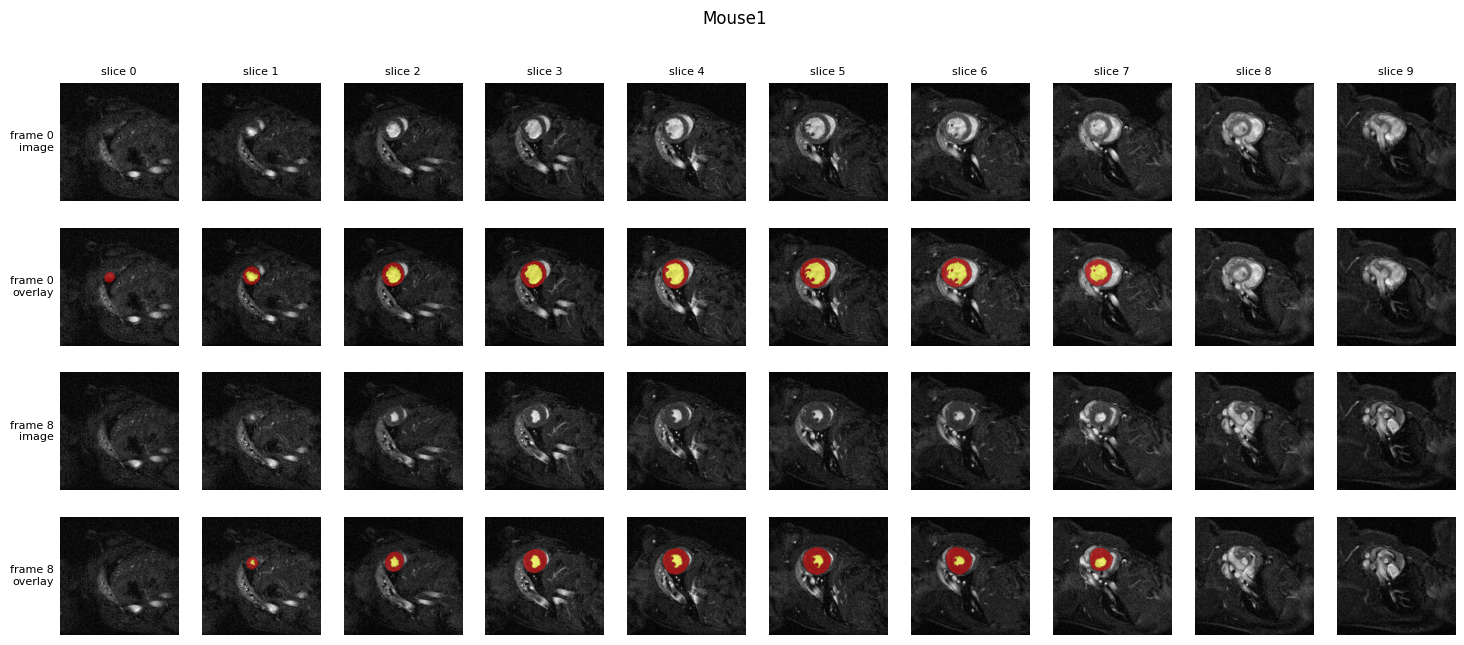

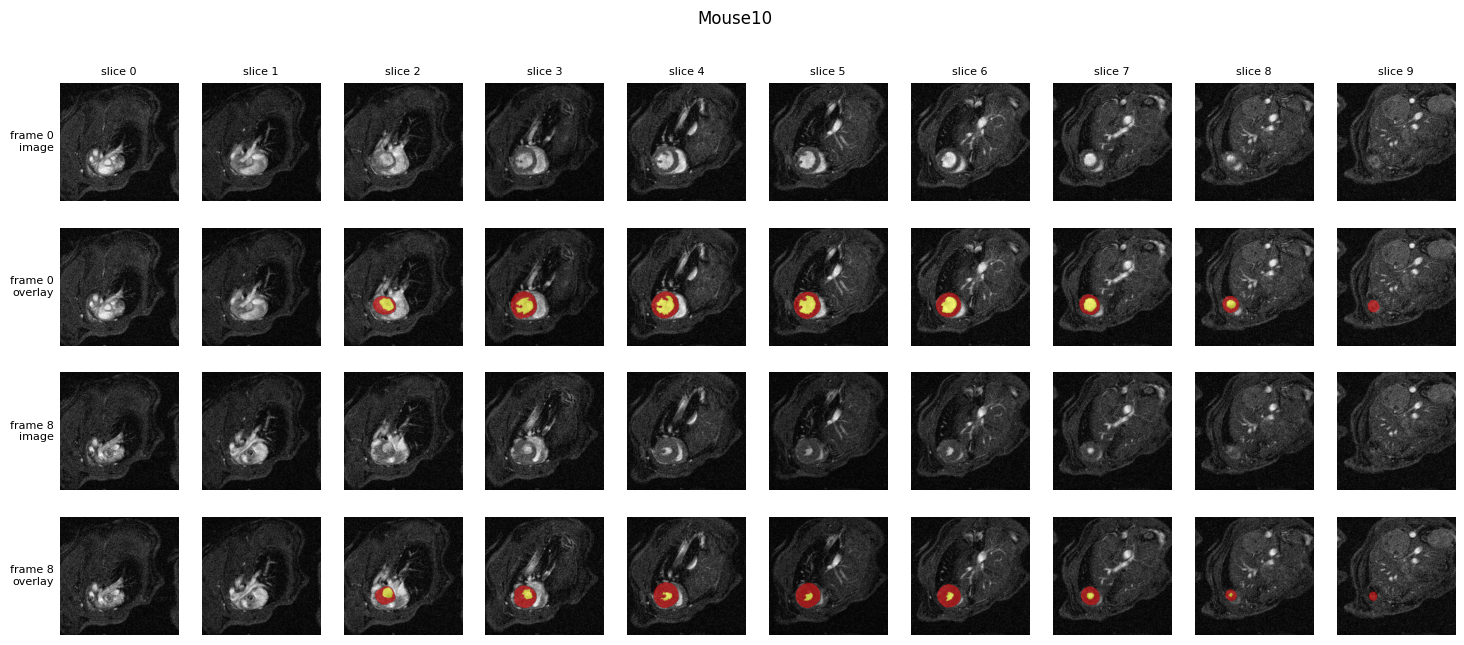

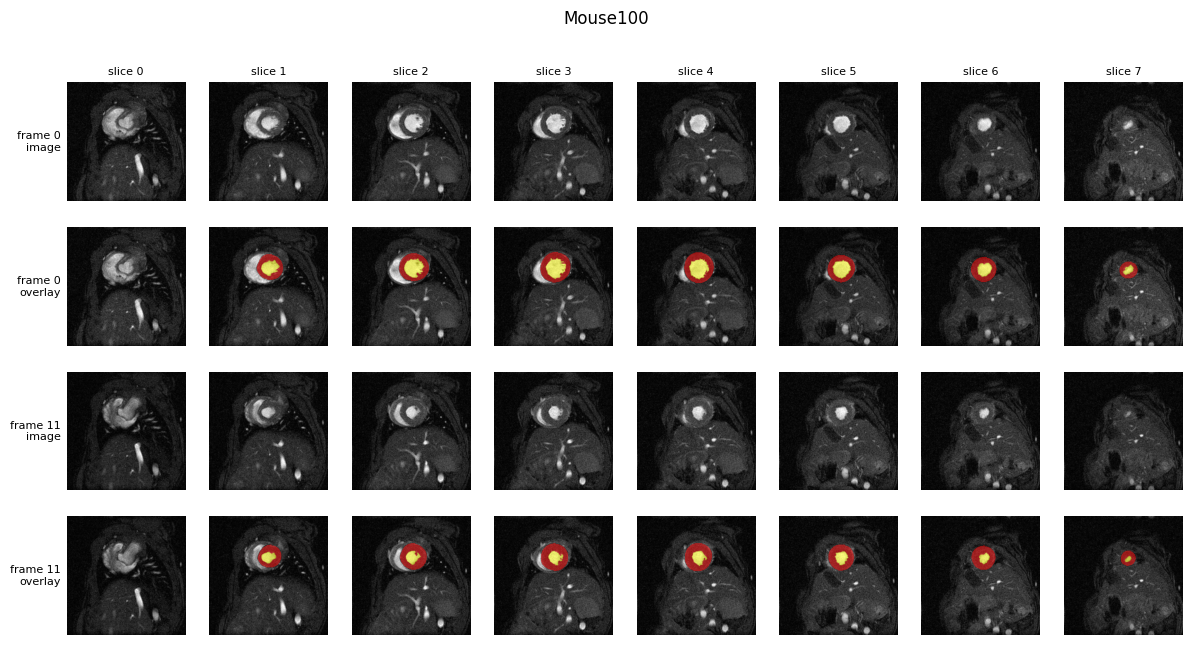

Saved 130 overlay images to output/step7_overlays/


In [ ]:

# %% STEP 7: look at the images (always do this with image data)
# One PNG per mouse is saved in output/step7_overlays/ (e.g. Mouse100.png).
# Each PNG shows the frames that have expert masks (end-diastole / end-systole):
# an image row and an overlay row for each frame, all slices left to right.
N_SHOW_INLINE = 3        # how many to also display in the notebook
MAX_MICE = None          # set to e.g. 20 to only save the first 20 mice

def frames_to_draw(path, mk, max_frames=2):
    """Use Frames_with_ROI when it agrees with the masks. A few mice have masks on
    11-17 frames, so we cap the figure at max_frames instead of drawing them all."""
    has = np.where((mk > 0).any(axis=(0, 2, 3)))[0]
    with h5py.File(path, "r") as f:
        roi = [int(x) for x in f["Frames_with_ROI"][()]] if "Frames_with_ROI" in f else []
    frames = [fr for fr in roi if fr in has][:max_frames]
    if not frames:
        frames = has[:max_frames].tolist() or [0]
    return frames

def show_mouse(path, show=True):
    im, mk = load_mouse(path)                                   # (S, F, H, W)
    frames = frames_to_draw(path, mk)
    n = im.shape[0]
    fig, axes = plt.subplots(2 * len(frames), n, figsize=(1.8 * n, 3.6 * len(frames)),
                             squeeze=False)
    for k, fr in enumerate(frames):
        for s in range(n):
            a_img, a_ov = axes[2 * k, s], axes[2 * k + 1, s]
            a_img.imshow(im[s, fr], cmap="gray")
            a_ov.imshow(im[s, fr], cmap="gray")
            a_ov.imshow(np.ma.masked_equal(mk[s, fr], 0), cmap="autumn", alpha=0.5)
            if k == 0:
                a_img.set_title(f"slice {s}", fontsize=8)
            a_img.axis("off"); a_ov.axis("off")
        axes[2 * k, 0].text(-0.05, 0.5, f"frame {fr}\nimage", transform=axes[2 * k, 0].transAxes,
                            ha="right", va="center", fontsize=8)
        axes[2 * k + 1, 0].text(-0.05, 0.5, f"frame {fr}\noverlay",
                                transform=axes[2 * k + 1, 0].transAxes,
                                ha="right", va="center", fontsize=8)
    name = os.path.splitext(os.path.basename(path))[0]
    plt.suptitle(name)
    save_fig(f"{name}.png", folder=OVERLAY_DIR, show=show)

to_plot = files if MAX_MICE is None else files[:MAX_MICE]
for i, p in enumerate(to_plot):
    show_mouse(p, show=(i < N_SHOW_INLINE))
print(f"Saved {len(to_plot)} overlay images to {OVERLAY_DIR}/")


## Step 8: which frames and slices have masks?
Counts the labeled frames, slices and 2D images per mouse. These counts decide how many training examples we have.

**From our run:** 130 mice, 2,208 labeled 2D slices in total (12–87 per mouse). Most mice have exactly 2 labeled frames, but mice 17, 48, 91 and 125 have masks on 11–17 frames. We need to decide whether to train on all of those frames or only the two `Frames_with_ROI` frames.

In [ ]:
# %% STEP 8: which frames/slices actually have masks?
# Your proposal says you'll use "timeframes with expert masks", so count them.
labeled = []
for p in files:
    _, mk = load_mouse(p)
    has = (mk > 0).any(axis=(2, 3))          # (S, F) True where a mask exists
    labeled.append({"file": os.path.basename(p),
                    "labeled_slices": int(has.any(axis=1).sum()),
                    "labeled_frames": int(has.any(axis=0).sum()),
                    "labeled_2d_images": int(has.sum())})
lab = pd.DataFrame(labeled)
lab.to_csv(os.path.join(OUT_DIR, "step8_labeled_counts.csv"), index=False)
print(lab.describe())
print("Total labeled 2D slices available for training:", lab["labeled_2d_images"].sum())


       labeled_slices  labeled_frames  labeled_2d_images
count      130.000000      130.000000         130.000000
mean         7.815385        2.338462          16.984615
std          0.744849        1.951163           9.397331
min          6.000000        2.000000          12.000000
25%          7.000000        2.000000          14.000000
50%          8.000000        2.000000          16.000000
75%          8.000000        2.000000          16.000000
max          9.000000       17.000000          87.000000
Total labeled 2D slices available for training: 2208


## Step 9: size of each class
Pixel area of myocardium (`area_1`) and blood pool (`area_2`) for every labeled slice. Apical and basal slices should be smaller. The background class is much larger than either heart class (class imbalance), which is why Dice is the right metric and a Dice-based loss is worth considering.

             slice        frame       area_1       area_2
count  2208.000000  2208.000000  2208.000000  2208.000000
mean      4.360507     6.086504  1408.608243   708.937953
std       2.334415     6.238591   545.561854   495.910707
min       0.000000     0.000000   122.000000     0.000000
25%       2.000000     0.000000  1049.000000   360.000000
50%       4.000000     8.000000  1413.000000   607.500000
75%       6.000000    10.000000  1763.250000  1005.250000
max      10.000000    29.000000  3110.000000  3708.000000


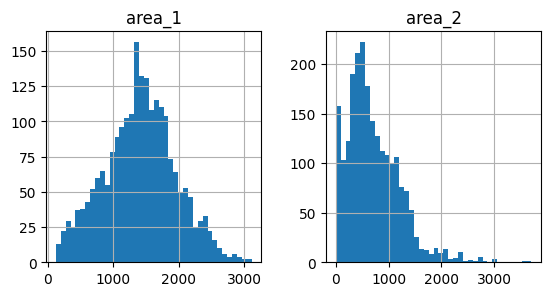

'output/step9_area_histograms.png'

In [ ]:
# %% STEP 9: LV size and myocardium thickness-ish stats across slices
# Pixel area per class per labeled slice; apical/basal slices should be smaller.
area_rows = []
for p in files:
    _, mk = load_mouse(p)
    for s in range(mk.shape[0]):
        for fr in range(mk.shape[1]):
            m = mk[s, fr]
            if (m > 0).any():
                d = {"file": os.path.basename(p), "slice": s, "frame": fr}
                for l in np.unique(mk):
                    if l != 0:
                        d[f"area_{int(l)}"] = int((m == l).sum())
                area_rows.append(d)
areas = pd.DataFrame(area_rows)
areas.to_csv(os.path.join(OUT_DIR, "step9_areas.csv"), index=False)
print(areas.describe())
areas.filter(like="area_").hist(bins=40, figsize=(10, 3), layout=(1, 3))
save_fig("step9_area_histograms.png")


## Step 10: train / validation / test split by mouse
A random 70/15/15 split of the 130 **mice** (not slices), so slices from one animal never end up in different sets (this avoids leakage between correlated slices). Fixed seed `42`; the split is saved to `output/step10_split.csv`. Part 2 (step 4) can be used to check that the three sets have similar heart sizes and image quality.

In [ ]:
# %% STEP 10: sanity checks for the train/val/test split by mouse (70/15/15)
SEED = 42                      # fixed seed -> the same split every run
rng = np.random.default_rng(SEED)
mice = np.array([os.path.basename(p) for p in files])
rng.shuffle(mice)
n = len(mice); n_tr, n_va = int(0.70 * n), int(0.15 * n)
split = {"train": mice[:n_tr], "val": mice[n_tr:n_tr + n_va], "test": mice[n_tr + n_va:]}
print({k: len(v) for k, v in split.items()})
# Save the exact split so model training later uses the identical train/val/test mice.
pd.DataFrame([(m, k) for k, v in split.items() for m in v],
             columns=["mouse", "set"]).to_csv(os.path.join(OUT_DIR, "step10_split.csv"), index=False)
# The split is by mouse, not by slice, so correlated slices from one animal
# never leak across sets (matches the proposal).


{'train': 91, 'val': 19, 'test': 20}


# Part 2: label quality, heart size/shape, image quality

**Settings and assumptions (marked `# PARAM` in the code)**
- Label `1` = myocardium, `2` = blood pool (confirmed by a majority vote in step 1).
- End-diastole (ED) = the labeled frame with the larger blood pool, end-systole (ES) = the one with the smaller blood pool.
- Background for noise estimates = pixels more than 15 px from any mask.
- A mouse is an image-quality outlier if any feature is beyond 3 SD.
- All sizes are in **pixels** (the physical pixel size is not used here), so compare between mice, not to real-world units.
- This cell reloads the raw arrays in `(H, W, slice, frame)` order with its own function `load_raw`, so it does not interfere with part 1's `load_mouse`.

In [ ]:
# Mouse cardiac MRI EDA, part 2 (Spider-Sense / DS 4002)
# Label quality, heart size/shape, image quality across mice.
# Self-contained: run it as its own notebook section after the repo is cloned.
# Each "# %%" block is a notebook cell.


# %% STEP 0: setup
import glob, os
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

DATA_DIR = os.environ.get("DATA_DIR", "Open-Source_Pre-Clinical_Segmentation/Data")

# Part 2 saves into output/part2/ so it doesn't mix with the part 1 files.
# (Own names, so re-running part 1 cells afterwards still saves to output/.)
P2_DIR = os.path.join(os.environ.get("OUT_DIR", "output"), "part2")
os.makedirs(P2_DIR, exist_ok=True)

def save_fig_p2(name, show=True):
    path = os.path.join(P2_DIR, name)
    plt.savefig(path, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close()
    return path

files = sorted(glob.glob(os.path.join(DATA_DIR, "*.h5")))
print(len(files), "files")

IMG_KEY, MASK_KEY = "Images", "Masks"       # arrays are (H, W, slice, frame)
# Which label is which? Step 1 checks this automatically; confirm visually.
MYO_LABEL, POOL_LABEL = 1, 2

def load_raw(path):
    with h5py.File(path, "r") as f:
        img = f[IMG_KEY][()].astype(np.float32)   # (H, W, S, F)
        msk = f[MASK_KEY][()]
    return img, msk


130 files


### Part 2, step 1: which label is which?
A myocardium mask is a ring, so filling its holes should swallow the blood pool. The label that does this most often is the myocardium.

**From our run:** label 1 won every vote (70/70), so `MYO_LABEL = 1`, `POOL_LABEL = 2` is correct.

In [ ]:
# %% STEP 1: which label is myocardium and which is blood pool?
# Myocardium is a ring: filling its holes should swallow the blood pool.
def guess_labels(files, n_mice=5):   # PARAM: checks the first 5 mice
    votes = {}
    for p in files[:n_mice]:
        _, mk = load_raw(p)
        for s in range(mk.shape[2]):
            for fr in range(mk.shape[3]):
                m = mk[:, :, s, fr]
                labs = [l for l in np.unique(m) if l != 0]
                if len(labs) < 2:
                    continue
                gains = {}
                for l in labs:
                    filled = ndi.binary_fill_holes(m == l)
                    gains[l] = int((filled & (m != l) & (m > 0)).sum())
                myo = int(max(gains, key=gains.get))
                votes[myo] = votes.get(myo, 0) + 1
    return votes

votes = guess_labels(files)
print("Label that encloses the other (likely myocardium), vote counts:", votes)
print("Current setting: MYO_LABEL =", MYO_LABEL, " POOL_LABEL =", POOL_LABEL)
# If the winning label differs from MYO_LABEL, swap the two values above.


Label that encloses the other (likely myocardium), vote counts: {1: 70}
Current setting: MYO_LABEL = 1  POOL_LABEL = 2


### Part 2, step 2: one pass over all mice
Computes, for every labeled slice, the areas, number of connected components, whether the blood pool is enclosed by the myocardium, and a wall-thickness estimate (equivalent-circle radius difference). For every mouse it also computes signal and noise measures (SNR/CNR). Results are saved as CSVs in `output/part2/`.

**Caveat:** for mice with masks on many frames (17, 48, 91, 125), ED and ES are picked from among all of their labeled frames, so their ED/ES may not be the frames the experts intended.

In [ ]:
# %% STEP 2: one pass over all mice, compute everything we need
def n_components(binary):
    return ndi.label(binary)[1]

def band_mean(img2d, mask, default=np.nan):
    return float(img2d[mask].mean()) if mask.any() else default

slice_rows, mouse_rows = [], []
for p in files:
    name = os.path.basename(p)
    try:
        img, msk = load_raw(p)
    except Exception as e:
        print("could not read", name, e); continue
    H, W, S, F = msk.shape
    has = (msk > 0).any(axis=(0, 1))                 # (S, F)
    lab_frames = np.where(has.any(axis=0))[0]
    if len(lab_frames) == 0:
        print("no masks in", name); continue

    # total blood-pool area per labeled frame -> larger = ED, smaller = ES
    pool_tot = {fr: int((msk[:, :, :, fr] == POOL_LABEL).sum()) for fr in lab_frames}
    ed = max(pool_tot, key=pool_tot.get)
    es = min(pool_tot, key=pool_tot.get)
    if len(lab_frames) != 2:
        print(f"{name}: {len(lab_frames)} labeled frames {lab_frames.tolist()} (expected 2)")

    for fr in lab_frames:
        phase = "ED" if fr == ed else ("ES" if fr == es else "other")
        for s in range(S):
            m = msk[:, :, s, fr]
            myo, pool = (m == MYO_LABEL), (m == POOL_LABEL)
            a_m, a_p = int(myo.sum()), int(pool.sum())
            r_in = np.sqrt(a_p / np.pi)
            r_out = np.sqrt((a_p + a_m) / np.pi)
            slice_rows.append({
                "file": name, "frame": int(fr), "phase": phase, "slice": s,
                "labeled": (a_m + a_p) > 0,
                "area_myo": a_m, "area_pool": a_p,
                "n_comp_myo": n_components(myo), "n_comp_pool": n_components(pool),
                "pool_enclosed": bool(a_p > 0 and
                                      (ndi.binary_fill_holes(myo) & pool).sum() == a_p),
                "thickness_px": (r_out - r_in) if (a_m > 0 and a_p > 0) else np.nan,
                "other_labels": int(((m != 0) & (m != MYO_LABEL) & (m != POOL_LABEL)).sum()),
            })

        # image quality at this frame (all labeled slices pooled)
        im = img[:, :, :, fr]
        mk = msk[:, :, :, fr]
        heart = mk > 0
        near_heart = ndi.binary_dilation(heart, iterations=15)  # PARAM: background = pixels >15 px from any mask
        bg = ~near_heart
        pool_m, myo_m = mk == POOL_LABEL, mk == MYO_LABEL
        sig_pool, sig_myo = band_mean(im, pool_m), band_mean(im, myo_m)
        bg_mean = band_mean(im, bg)
        bg_std = float(im[bg].std()) if bg.any() else np.nan
        mouse_rows.append({
            "file": name, "phase": phase, "frame": int(fr),
            "pool_mean": sig_pool, "myo_mean": sig_myo,
            "bg_mean": bg_mean, "bg_std": bg_std,
            "pool_myo_ratio": sig_pool / sig_myo if sig_myo else np.nan,
            "CNR": (sig_pool - sig_myo) / bg_std if bg_std else np.nan,
            "SNR_pool": (sig_pool - bg_mean) / bg_std if bg_std else np.nan,
            "img_max": float(im.max()),
        })

sl = pd.DataFrame(slice_rows)
mq = pd.DataFrame(mouse_rows)
print(sl.shape, mq.shape)
sl.to_csv(os.path.join(P2_DIR, "slice_features.csv"), index=False)
mq.to_csv(os.path.join(P2_DIR, "mouse_image_quality.csv"), index=False)


Mouse125.h5: 11 labeled frames [0, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18] (expected 2)
Mouse17.h5: 12 labeled frames [0, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19] (expected 2)
Mouse48.h5: 12 labeled frames [0, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20] (expected 2)
Mouse91.h5: 17 labeled frames [0, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29] (expected 2)
(2833, 12) (304, 11)


### 3A: label quality
A clean mask has one myocardium component, one blood-pool component, and a pool fully inside the ring. Slices that fail any of these are flagged for visual review (saved to `step3a_flagged_slices.csv`).

**From our run:** 190 of 2,208 labeled slices (8.6%) were flagged. 95.3% of slices have the pool fully enclosed. 103 slices have a myocardium mask but no blood-pool mask. Masks are emptiest at the slice ends (74% of slice 0 and 50% of slice 9 have no mask). No unexpected label values.

Slices per mouse x labeled frame: 2833  -> with a mask: 2208

Slices with NO mask, by slice index (apex/base are usually partial):
slice
0     0.74
1     0.36
2     0.08
3     0.00
4     0.00
5     0.02
6     0.11
7     0.16
8     0.42
9     0.50
10    0.25
Name: frac_empty, dtype: float64

Connected components per mask (clean = 1 myo, 1 pool):
pool comps    0     1   2  3
myo comps                   
1           103  2018  17  2
2             0    58   0  0
3             0     5   0  0
4             0     4   0  0
5             0     1   0  0

Pool fully enclosed by myocardium ring: 0.953
Pixels with unexpected label values: 0

190 slices flagged for review (of 2208):
            file phase  slice  n_comp_myo  n_comp_pool  pool_enclosed
0      Mouse1.h5    ED      0           1            0          False
6      Mouse1.h5    ED      6           2            1           True
7      Mouse1.h5    ED      7           2            1           True
29    Mouse10.h5    ED      9           1 

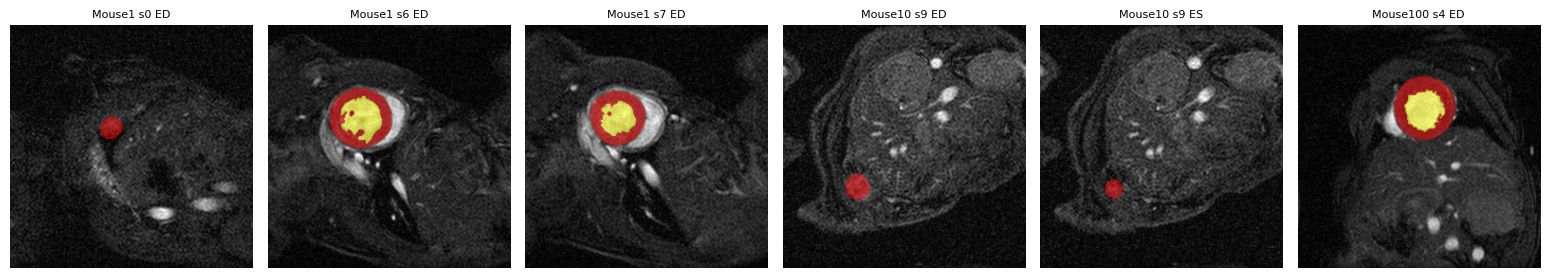

In [ ]:
# %% STEP 3A: label quality
lab = sl[sl["labeled"]]
print("Slices per mouse x labeled frame:", len(sl), " -> with a mask:", len(lab))
print("\nSlices with NO mask, by slice index (apex/base are usually partial):")
print(sl.groupby("slice")["labeled"].apply(lambda x: 1 - x.mean()).round(2).rename("frac_empty"))

print("\nConnected components per mask (clean = 1 myo, 1 pool):")
print(pd.crosstab(lab["n_comp_myo"], lab["n_comp_pool"], rownames=["myo comps"], colnames=["pool comps"]))
print("\nPool fully enclosed by myocardium ring:", lab["pool_enclosed"].mean().round(3))
print("Pixels with unexpected label values:", int(sl["other_labels"].sum()))

flag = lab[(lab["n_comp_myo"] != 1) | (lab["n_comp_pool"] != 1) | (~lab["pool_enclosed"])]
print(f"\n{len(flag)} slices flagged for review (of {len(lab)}):")
print(flag[["file", "phase", "slice", "n_comp_myo", "n_comp_pool", "pool_enclosed"]].head(25))

# Look at a few flagged slices
def show_flagged(df, k=6):
    df = df.head(k)
    if df.empty:
        print("nothing flagged"); return
    fig, axes = plt.subplots(1, len(df), figsize=(2.6 * len(df), 3), squeeze=False)
    for ax, (_, r) in zip(axes[0], df.iterrows()):
        im, mk = load_raw(os.path.join(DATA_DIR, r["file"]))
        ax.imshow(im[:, :, r["slice"], r["frame"]], cmap="gray")
        ax.imshow(np.ma.masked_equal(mk[:, :, r["slice"], r["frame"]], 0), cmap="autumn", alpha=0.5)
        ax.set_title(f'{r["file"][:-3]} s{r["slice"]} {r["phase"]}', fontsize=8); ax.axis("off")
    plt.tight_layout(); save_fig_p2("step3a_flagged_masks.png")

flag.to_csv(os.path.join(P2_DIR, "step3a_flagged_slices.csv"), index=False)
show_flagged(flag)


### 3B: heart size and shape
Base-to-apex profiles of cavity area, myocardium area and wall thickness at ED and ES; an area-based ejection-fraction proxy per mouse ((ED − ES) / ED, summed over slices); and a heatmap of where the heart sits in the 256×256 frame. The EF proxy is a rough 2D estimate, not a true volume-based EF. Index 0 may be base or apex depending on the acquisition, so check against the overlays.

**From our run:** the EF proxy averages 0.55 (range 0.15–0.87); every mouse has a smaller ES than ED cavity. Mean wall thickness is about 9.9 px at ED and 13.2 px at ES. The heart occupies roughly rows 53–206 and columns 49–201, so cropping around the center is possible.

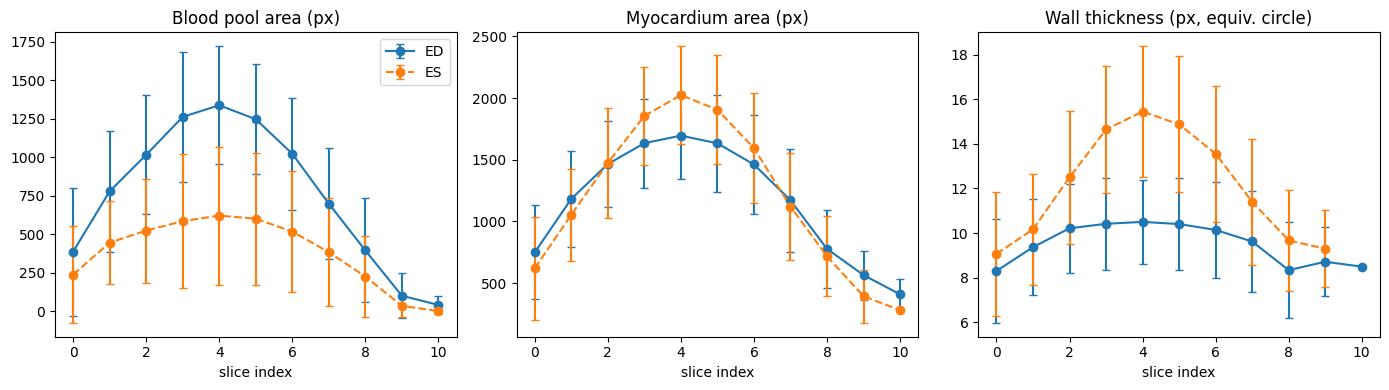

phase         ED         ES  EF_proxy  thick_ED  thick_ES
count    130.000    130.000   130.000   130.000   130.000
mean    7412.354   3630.623     0.549     9.922    13.172
std     2737.604   2764.708     0.147     1.677     2.023
min     4483.000    733.000     0.154     5.021     6.240
25%     6026.500   2057.250     0.458     8.961    12.146
50%     6788.000   2842.500     0.579     9.777    13.568
75%     7423.000   4115.000     0.653    10.930    14.415
max    19915.000  16845.000     0.869    13.807    17.053

Mice where ES cavity is NOT smaller than ED (check these): 0
Empty DataFrame
Columns: [ED, ES, EF_proxy, thick_ED, thick_ES]
Index: []


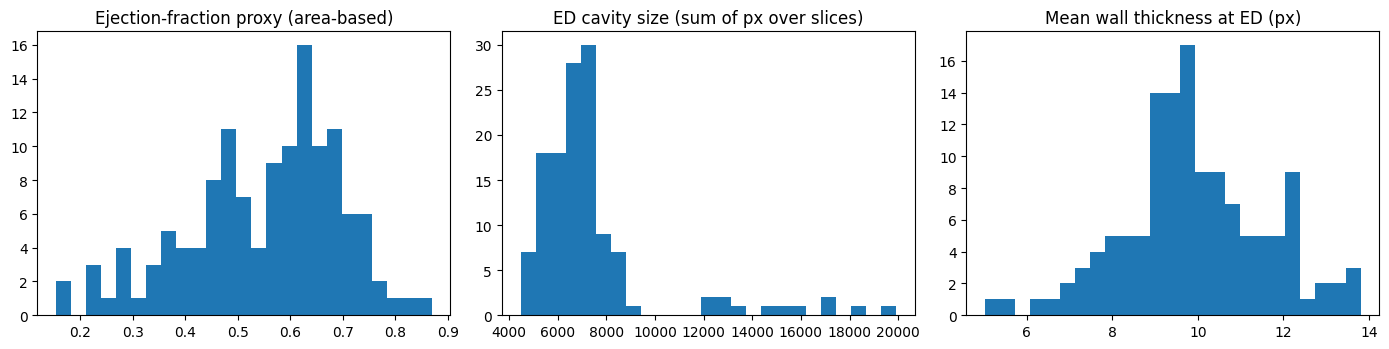

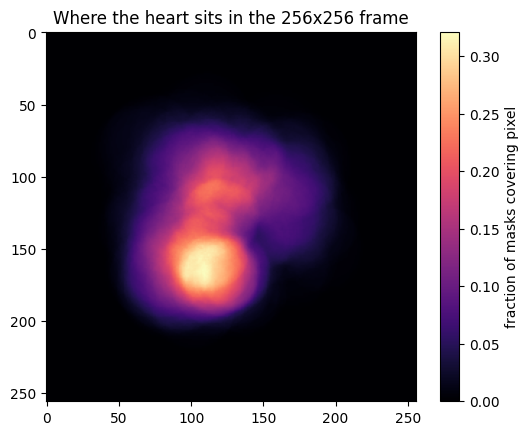

Region covered by >2% of masks: rows 53 - 206  cols 49 - 201


In [ ]:
# %% STEP 3B: heart size and shape
# Base-to-apex profile of cavity and myocardium area, ED vs ES
prof = lab[lab["phase"].isin(["ED", "ES"])]
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for phase, ls in [("ED", "-"), ("ES", "--")]:
    g = prof[prof["phase"] == phase].groupby("slice")
    for col, a, title in [("area_pool", ax[0], "Blood pool area (px)"),
                          ("area_myo", ax[1], "Myocardium area (px)"),
                          ("thickness_px", ax[2], "Wall thickness (px, equiv. circle)")]:
        mean, sd = g[col].mean(), g[col].std()
        a.errorbar(mean.index, mean.values, yerr=sd.values, ls=ls, marker="o", capsize=3, label=phase)
        a.set_title(title); a.set_xlabel("slice index")
ax[0].legend(); plt.tight_layout(); save_fig_p2("step3b_base_to_apex_profiles.png")
# Slice index 0 vs 9: whether index 0 is base or apex depends on the acquisition;
# check against the overlays from part 1.

# Per-mouse volume proxy and ejection-fraction proxy (sum of pool area over slices)
vol = prof.groupby(["file", "phase"])["area_pool"].sum().unstack()
vol["EF_proxy"] = (vol["ED"] - vol["ES"]) / vol["ED"]
mthick = prof.groupby(["file", "phase"])["thickness_px"].mean().unstack().add_prefix("thick_")
mouse = vol.join(mthick)
print(mouse.describe().round(3))
bad = mouse[mouse["EF_proxy"] <= 0]
print(f"\nMice where ES cavity is NOT smaller than ED (check these): {len(bad)}")
print(bad)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].hist(mouse["EF_proxy"].dropna(), bins=25); ax[0].set_title("Ejection-fraction proxy (area-based)")
ax[1].hist(mouse["ED"], bins=25); ax[1].set_title("ED cavity size (sum of px over slices)")
ax[2].hist(mouse["thick_ED"].dropna(), bins=25); ax[2].set_title("Mean wall thickness at ED (px)")
plt.tight_layout(); save_fig_p2("step3b_ef_size_thickness_hists.png")
mouse.to_csv(os.path.join(P2_DIR, "mouse_morphology.csv"))

# Where is the heart in the frame? average mask across mice
heat = np.zeros((256, 256))
n = 0
for p in files:
    _, mk = load_raw(p)
    lf = np.where((mk > 0).any(axis=(0, 1)).any(axis=0))[0]
    for fr in lf:
        for s in range(mk.shape[2]):
            if (mk[:, :, s, fr] > 0).any():
                heat += (mk[:, :, s, fr] > 0); n += 1
plt.imshow(heat / n, cmap="magma"); plt.colorbar(label="fraction of masks covering pixel")
plt.title("Where the heart sits in the 256x256 frame"); save_fig_p2("step3b_heart_location_heatmap.png")
ys, xs = np.where(heat / n > 0.02)  # PARAM: region covered by >2% of masks
print("Region covered by >2% of masks: rows", ys.min(), "-", ys.max(), " cols", xs.min(), "-", xs.max())


### 3C: image quality across mice
Signal-to-noise (SNR) and contrast-to-noise (CNR) per mouse at ED, outliers beyond 3 SD, and a PCA of these features. Clusters or outliers show scan-to-scan variation that the model will have to handle on unseen mice.

**From our run:** 6 mice are outliers (Mouse111, Mouse12, Mouse23, Mouse38, Mouse82, Mouse96). Mice 111, 12 and 96 are unusually dark overall; 23 and 38 have unusually high SNR/CNR; 82 has an unusually high blood-pool/myocardium ratio.

       pool_mean  myo_mean  bg_mean  bg_std  pool_myo_ratio     CNR  SNR_pool
count     130.00    130.00   130.00  130.00          130.00  130.00    130.00
mean     1353.78    598.01   239.62  204.09            2.31    3.77      5.53
std       187.12    126.62    47.99   34.58            0.34    0.73      0.72
min       664.28    282.60   109.81  101.09            1.70    2.11      3.55
25%      1314.05    513.43   211.55  191.98            2.04    3.27      5.15
50%      1407.70    585.34   243.73  206.39            2.28    3.72      5.50
75%      1463.22    669.65   275.15  221.61            2.53    4.29      5.91
max      1653.93    951.30   365.98  283.94            3.54    5.62      7.77

Mice with any quality feature beyond 3 SD: 6
             pool_mean  myo_mean  bg_mean  bg_std  pool_myo_ratio  CNR  \
file                                                                     
Mouse111.h5       -3.7      -2.5     -2.7    -3.0             0.1  0.0   
Mouse12.h5        -3.5      -1

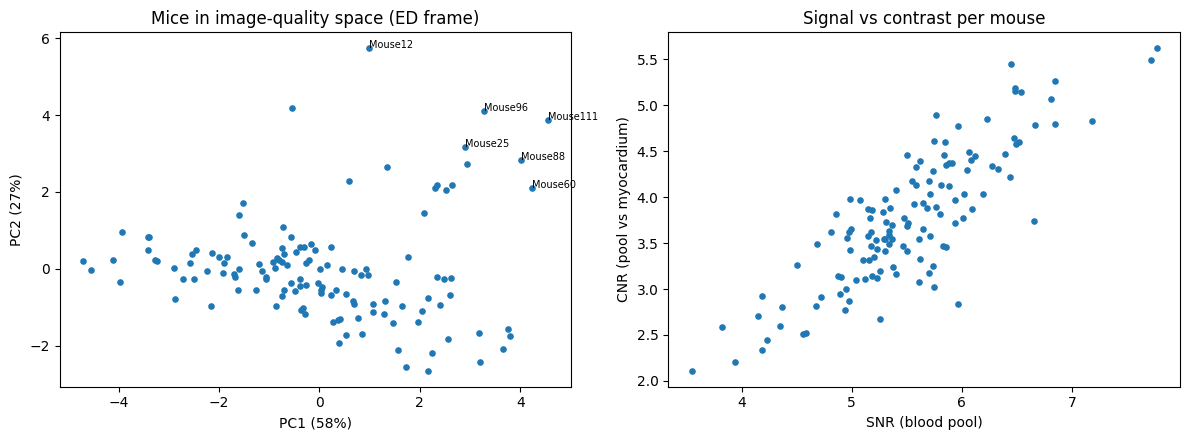

In [ ]:
# %% STEP 3C: image quality across mice
feat_cols = ["pool_mean", "myo_mean", "bg_mean", "bg_std", "pool_myo_ratio", "CNR", "SNR_pool"]
q = mq[mq["phase"] == "ED"].set_index("file")[feat_cols]
print(q.describe().round(2))

# z-scores and outliers
z = (q - q.mean()) / q.std()
out = z[(z.abs() > 3).any(axis=1)]                    # PARAM: outlier = beyond 3 SD on any feature
print(f"\nMice with any quality feature beyond 3 SD: {len(out)}")
print(out.round(1))

# PCA by SVD
X = z.fillna(0).values
U, Sg, Vt = np.linalg.svd(X, full_matrices=False)
pcs = U[:, :2] * Sg[:2]
var = (Sg ** 2 / (Sg ** 2).sum())[:2]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(pcs[:, 0], pcs[:, 1], s=14)
for i in np.argsort(-np.abs(pcs[:, 0]) - np.abs(pcs[:, 1]))[:6]:
    ax[0].annotate(q.index[i][:-3], pcs[i], fontsize=7)
ax[0].set_xlabel(f"PC1 ({var[0]:.0%})"); ax[0].set_ylabel(f"PC2 ({var[1]:.0%})")
ax[0].set_title("Mice in image-quality space (ED frame)")
ax[1].scatter(q["SNR_pool"], q["CNR"], s=14)
ax[1].set_xlabel("SNR (blood pool)"); ax[1].set_ylabel("CNR (pool vs myocardium)")
ax[1].set_title("Signal vs contrast per mouse")
plt.tight_layout(); save_fig_p2("step3c_image_quality_pca.png")
out.to_csv(os.path.join(P2_DIR, "step3c_quality_outliers.csv"))
# Clusters or a long tail here = scan-to-scan variation the model must generalize across.


### Part 2, step 4: relationships between heart size and image quality
Correlations between the EF proxy, ED cavity size, wall thickness, SNR and CNR.

**From our run:** the EF proxy and ED cavity size are strongly negatively correlated (−0.73), SNR and CNR are strongly positively correlated (0.84), and CNR is moderately related to wall thickness (0.49).

In [ ]:
# %% STEP 4: link image quality to heart size (does either affect the other?)
joined = mouse.join(q, how="inner")
corr = joined[["EF_proxy", "ED", "thick_ED", "SNR_pool", "CNR"]].corr().round(2)
print(corr)
corr.to_csv(os.path.join(P2_DIR, "step4_correlations.csv"))


          EF_proxy    ED  thick_ED  SNR_pool   CNR
EF_proxy      1.00 -0.73     -0.02     -0.04 -0.16
ED           -0.73  1.00     -0.40     -0.13 -0.06
thick_ED     -0.02 -0.40      1.00      0.27  0.49
SNR_pool     -0.04 -0.13      0.27      1.00  0.84
CNR          -0.16 -0.06      0.49      0.84  1.00


## Download everything
Zips `output/` and downloads it. Do this before closing Colab, because the runtime (and `output/`) is deleted when the session resets.

In [ ]:
import shutil
from google.colab import files

shutil.make_archive("eda_output", "zip", "output")   # eda_output.zip with output/'s contents
files.download("eda_output.zip")
